# تحت سماء واحدة


####«قد تختلف معاني الكلمات وتتشابه سياقاتها، فهل تتشكل تمثيلاتها في فضاء واحد رغم اختلاف معانيها؟»

## Arabic Contextual Word Representations: Semantic Relations in Similar Contexts

### Research Question

* إذا رأى نموذج لغوي كلمتين في سياقات متشابهة، فهل سيضع تمثيلاتهما متقاربة رغم اختلافهما في الكتابة وتضادهما في المعنى؟
* If a language model sees two words in similar contexts, will it place their representations close together even if they differ in spelling and are opposite in meaning?

### Motivation

جاءت فكرة المشروع من العبارة الكورية

«사랑과 증오가 같은 말이면 i love seoul, i hate seoul »

 والتي تفترض ان الحب والكراهية يمثلان الكلمة نفسها.  وقد دفعت هذه العبارة إلى التساؤل حول العلاقة بين تشابه السياقات اللغوية وتشابه تمثيلات الكلمات: هل يمكن أن تتقارب تمثيلات كلمتين متضادتين في المعنى إذا ظهرتا في سياقات متشابهة؟

### Dataset:
[Arabic-NLi-Pair-Class](https://huggingface.co/datasets/Omartificial-Intelligence-Space/Arabic-NLi-Pair-Class)

### Model

[UBC-NLP/ARBERT](https://huggingface.co/UBC-NLP/ARBERT)

##1.GPU Setup and Libraries

In [1]:
!nvidia-smi  # display information about available NVIDIA GPUs

Tue Nov  3 07:20:59 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   46C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [2]:
import cudf
import cuml
import cupy as cp

print("cuDF Version :", cudf.__version__)
print("cuML Version :", cuml.__version__)
print("CuPy Version :", cp.__version__)

cuDF Version : 26.06.00
cuML Version : 26.06.00
CuPy Version : 14.0.1


In [3]:
# Display GPU information لمعرفة عدد GPU
print("Number of GPUs :", cp.cuda.runtime.getDeviceCount())
device = cp.cuda.Device(0)
print("Current GPU ID :", device.id)

Number of GPUs : 1
Current GPU ID : 0


In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F
from torch.optim import AdamW
from torch.utils.data import DataLoader
from datasets import load_dataset
from transformers import (AutoTokenizer, AutoModel, AutoModelForSequenceClassification,
                          DataCollatorWithPadding, get_linear_schedule_with_warmup, set_seed)
from sklearn.metrics import accuracy_score, f1_score, classification_report
from tqdm.auto import tqdm

SEED = 42
set_seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

Device: cuda


In [5]:
# to show Arabic words correctly in plot and heatmap
!pip -q install arabic-reshaper python-bidi

import arabic_reshaper
from bidi.algorithm import get_display

def ar(text):
    return get_display(arabic_reshaper.reshape(text))

##2.Download Arabic-NLi-Pair-Class Datasets

Arabic-NLi-Pair-Class has pairs of Arabic sentences (a premise and a hypothesis) with one label: entailment, neutral or contradiction. It already comes split into train, validation and test.

In [6]:
from datasets import load_dataset
ds = load_dataset("Omartificial-Intelligence-Space/Arabic-NLi-Pair-Class")

README.md:   0%|          | 0.00/2.21k [00:00<?, ?B/s]

train.csv: reconstructing file:   0%|          |  0.00B /  180MB            

train.csv: downloading bytes:           |  0.00B            

dev.csv:   0%|          | 0.00/3.98M [00:00<?, ?B/s]

test.csv:   0%|          | 0.00/4.19M [00:00<?, ?B/s]

Generating train split: 0 examples [00:00, ? examples/s]

Generating validation split: 0 examples [00:00, ? examples/s]

Generating test split: 0 examples [00:00, ? examples/s]

In [7]:
label_names = ds["train"].features["label"].names

for split in ds:
    print(split, "|", len(ds[split]), "rows")
print("Labels:", label_names)

train | 942069 rows
validation | 19657 rows
test | 19656 rows
Labels: ['entailment', 'neutral', 'contradiction']


##3.Exploratory Data Analysis


In [8]:
train_df = ds["train"].to_pandas()
val_df = ds["validation"].to_pandas()
test_df = ds["test"].to_pandas()

print("Train shape:", train_df.shape)
print("Validation shape:", val_df.shape)
print("Test shape:", test_df.shape)

Train shape: (942069, 3)
Validation shape: (19657, 3)
Test shape: (19656, 3)


In [9]:
train_df.head()

,premise,hypothesis,label
0,شخص على حصان يقفز فوق طائرة معطلة,شخص يقوم بتدريب حصانه للمنافسة,1
1,شخص على حصان يقفز فوق طائرة معطلة,شخص في مطعم، يطلب عجة.,2
2,شخص على حصان يقفز فوق طائرة معطلة,شخص في الهواء الطلق، على حصان.,0
3,أطفال يبتسمون و يلوحون للكاميرا,إنهم يبتسمون لوالديهم,1
4,أطفال يبتسمون و يلوحون للكاميرا,هناك أطفال حاضرون,0


In [10]:
train_df.sample(10, random_state=SEED)

,premise,hypothesis,label
762721,كان عليك القيام ببعض العمل,كان عليك القيام بالكثير من العمل للجيش,1
674347,الآخرين كانوا مجتمعين على بعد مسافة قصيرة,كان هناك مجموعة من الناس على مسافة قصيرة.,0
2362,طفل صغير يرتدي قميصًا أزرقًا وبنطالًا جينزًا أ...,طفل يركض على الأوراق.,0
913903,وود كوي ، على الضفة الجنوبية من النهر (تحت الم...,تقع المستوطنة الفايكنجية الأصلية واستجمامها ال...,0
204130,رجل مسن يبتسم ويحمل خيطاً,رجل كبير السن سوف يربط عقدة,1
220223,مجموعة من الناس في سترات النجاة يقفون على صخرة...,مجموعة من الناس على وشك الذهاب للسباحة,1
277414,رجلين يستمتعان ببيرة معاً,الرجلين ثملان.,1
788967,قضت محكمة الاستئناف على الوكالة لتكتيكات التخو...,لقد دعمت المحكمة الوكالة واعتقدت أن طريقة التع...,2
722422,تكساس نعم أنا في كاليفورنيا الآن أنا أنا أصلا ...,أحب (كاليفورنيا) أكثر من (كارولينا الشمالية),1
791949,الملابس لم تناسبني,الفستان لم يناسبني,1


In [11]:
# show dataset information
train_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 942069 entries, 0 to 942068
Data columns (total 3 columns):
 #   Column      Non-Null Count   Dtype 
---  ------      --------------   ----- 
 0   premise     942069 non-null  object
 1   hypothesis  942069 non-null  object
 2   label       942069 non-null  int64 
dtypes: int64(1), object(2)
memory usage: 21.6+ MB


In [12]:
# Show summary of all columns in the dataset
train_df.describe(include="all")

,premise,hypothesis,label
count,942069,942069,942069.000000
unique,335311,828351,NaN
top,[الصورة في الصفحة ٢٦],هناك رجل بالخارج,NaN
freq,142,660,NaN
mean,NaN,NaN,0.999761
std,NaN,NaN,0.816730
min,NaN,NaN,0.000000
25%,NaN,NaN,0.000000
50%,NaN,NaN,1.000000
75%,NaN,NaN,2.000000


In [13]:
# Check for the missing values
missing = train_df.isnull().sum()
missing_pct = ( train_df.isnull().sum() / len(train_df) * 100).round(2)
missing_table = pd.DataFrame({ "Missing Count": missing, "Missing Percentage": missing_pct})
missing_table.sort_values( by="Missing Count", ascending=False)

,Missing Count,Missing Percentage
premise,0,0.0
hypothesis,0,0.0
label,0,0.0


In [14]:
# Check exact duplicate rows in the training set
print("Exact duplicate rows:", train_df.duplicated().sum())

# Check repeated premise and hypothesis pairs, without looking at labels
pair_cols = ["premise", "hypothesis"]
print( "Repeated pair rows (excluding first occurrences):", train_df.duplicated(subset=pair_cols).sum())

duplicates = train_df[
    train_df.duplicated(subset=pair_cols, keep=False)
].sort_values(pair_cols)

display(duplicates.head(10))

Exact duplicate rows: 1277
Repeated pair rows (excluding first occurrences): 1753


,premise,hypothesis,label
707951,"""آسف""",أعتذر.,0
852769,"""آسف""",أعتذر.,0
785615,'أرى'.,أنا أفهم ذلك,0
881611,'أرى'.,أنا أفهم ذلك,0
676788,'أرى'.,أنا لا أفهم,2
859909,'أرى'.,أنا لا أفهم,2
684353,(انقر على موقع Chatterbox على موقع Snitchensgate.,أسداسد,1
840795,(انقر على موقع Chatterbox على موقع Snitchensgate.,أسداسد,0
574326,(بينما (مونيكا) في (برينتوود تزور والدها (في آ...,وفقًا لـ (يو إس إيه تي) ، لا يزال محامو (مونيك...,1
827811,(بينما (مونيكا) في (برينتوود تزور والدها (في آ...,وفقًا لـ (يو إس إيه تي) ، لا يزال محامو (مونيك...,0


In [15]:
# Check whether identical premise and hypothesis pairs have different labels
pair_label_counts = (train_df.groupby(["premise", "hypothesis"])["label"].nunique())

conflicting_pairs = pair_label_counts[pair_label_counts > 1]

print("Unique sentence pairs:", len(pair_label_counts))
print("Pairs with different labels:", len(conflicting_pairs))

if len(conflicting_pairs) > 0:
    conflict_examples = (
        train_df.set_index(["premise", "hypothesis"])
        .loc[conflicting_pairs.index]
        .reset_index()
        .sort_values(["premise", "hypothesis"])
    )

    display(conflict_examples.head(20))

Unique sentence pairs: 940316
Pairs with different labels: 453


,premise,hypothesis,label
0,(انقر على موقع Chatterbox على موقع Snitchensgate.,أسداسد,1
1,(انقر على موقع Chatterbox على موقع Snitchensgate.,أسداسد,0
2,(بينما (مونيكا) في (برينتوود تزور والدها (في آ...,وفقًا لـ (يو إس إيه تي) ، لا يزال محامو (مونيك...,1
3,(بينما (مونيكا) في (برينتوود تزور والدها (في آ...,وفقًا لـ (يو إس إيه تي) ، لا يزال محامو (مونيك...,0
4,(تشانغ)...,(تشانغ),1
5,(تشانغ)...,(تشانغ),2
6,(تشانغ)...,(تشانغ),0
7,(دانيال) نظر حوله، مندهش من عجلتي.,لقد تفاجأ (دانيال) بمدى إصراري,1
8,(دانيال) نظر حوله، مندهش من عجلتي.,لقد تفاجأ (دانيال) بمدى إصراري,0
9,(مجلس معايير المحاسبة المالية ، بيان معايير ال...,معايير المحاسبة المالية,0


In [16]:
# Count how many labels each repeated pair has
print("Number of pairs with 2 labels:",(pair_label_counts == 2).sum())
print("Number of pairs with 3 labels:",(pair_label_counts == 3).sum())

# Show the distribution of different labels
conflict_label_counts = (
    train_df.groupby(["premise", "hypothesis"])["label"]
    .agg(lambda labels: tuple(sorted(set(labels))))
    .reset_index(name="labels")
)

conflict_label_counts = conflict_label_counts[conflict_label_counts["labels"].apply(len) > 1]

display(conflict_label_counts.head(15))

Number of pairs with 2 labels: 430
Number of pairs with 3 labels: 23


,premise,hypothesis,labels
6186,(انقر على موقع Chatterbox على موقع Snitchensgate.,أسداسد,"(0, 1)"
7108,(بينما (مونيكا) في (برينتوود تزور والدها (في آ...,وفقًا لـ (يو إس إيه تي) ، لا يزال محامو (مونيك...,"(0, 1)"
7305,(تشانغ)...,(تشانغ),"(0, 1, 2)"
9101,(دانيال) نظر حوله، مندهش من عجلتي.,لقد تفاجأ (دانيال) بمدى إصراري,"(0, 1)"
12747,(مجلس معايير المحاسبة المالية ، بيان معايير ال...,معايير المحاسبة المالية,"(0, 1)"
13090,(نقل عن محرر التفاصيل أنه سأل نفسه، كيف يمكن ل...,كيف يمكن للرجل أن يثور اليوم؟,"(0, 2)"
13795,(ويس ويدماير),لا / لا,"(0, 1)"
14216,-بالطبع,بكل تأكيد,"(0, 1)"
14275,-كلا -كلا -كلا,لا,"(0, 2)"
14374,-ماذا يعني هذا؟,طلب (كيدان) توضيحاً,"(0, 1)"


{'entailment': np.int64(314315), 'neutral': np.int64(313664), 'contradiction': np.int64(314090)}


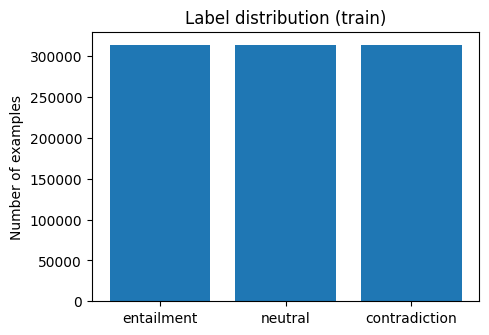

In [17]:
counts = train_df["label"].value_counts().sort_index()
print(dict(zip(label_names, counts.values)))

plt.figure(figsize=(5, 3.5))
plt.bar(label_names, counts.values)
plt.title("Label distribution (train)")
plt.ylabel("Number of examples")
plt.show()

In [18]:
# Character lengths before tokenization
train_df["premise_chars"] = train_df["premise"].str.len()
train_df["hypothesis_chars"] = train_df["hypothesis"].str.len()

print("Premise length statistics:")
display(train_df["premise_chars"].describe(
    percentiles=[0.50, 0.90, 0.95, 0.99]))

print("Hypothesis length statistics:")
display(train_df["hypothesis_chars"].describe(
    percentiles=[0.50, 0.90, 0.95, 0.99]))


Premise length statistics:


,premise_chars
count,942069.000000
mean,67.126931
std,44.975125
min,3.000000
50%,54.000000
90%,126.000000
95%,156.000000
99%,226.000000
max,713.000000


Hypothesis length statistics:


,hypothesis_chars
count,942069.000000
mean,35.540338
std,19.558863
min,1.000000
50%,31.000000
90%,61.000000
95%,73.000000
99%,100.000000
max,351.000000


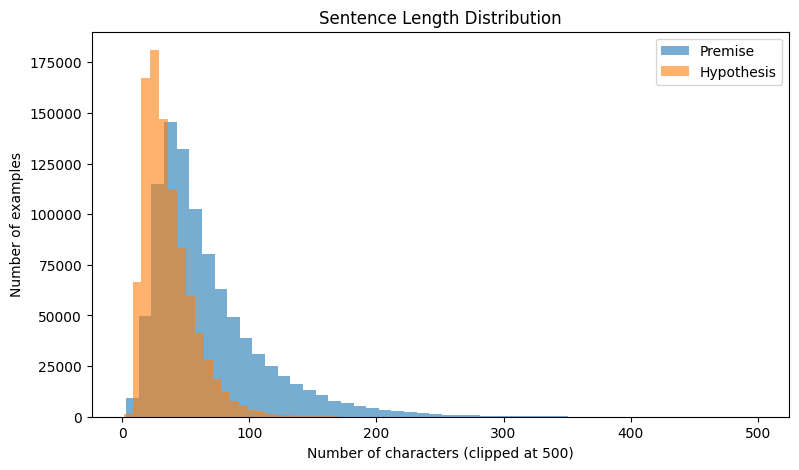

In [19]:
plt.figure(figsize=(9, 5))

plt.hist(
    train_df["premise_chars"].clip(upper=500),
    bins=50,
    alpha=0.6,
    label="Premise"
)

plt.hist(
    train_df["hypothesis_chars"].clip(upper=500),
    bins=50,
    alpha=0.6,
    label="Hypothesis"
)

plt.xlabel("Number of characters (clipped at 500)")
plt.ylabel("Number of examples")
plt.title("Sentence Length Distribution")
plt.legend()
plt.show()

In [20]:
# Check for overlapping sentence pairs between training, validation, and test sets
train_pairs = set(zip(train_df["premise"], train_df["hypothesis"]))
for name, other in [("validation", val_df), ("test", test_df)]:
    overlap = train_pairs & set(zip(other["premise"], other["hypothesis"]))
    print(f"Sentence pairs shared by train and {name}:", len(overlap))

Sentence pairs shared by train and validation: 3
Sentence pairs shared by train and test: 6


The three labels are almost balanced.

There are no missing values. We found 1,277 duplicate rows. and Repeated sentence pairs, including 453 unique pairs with more than one label.
We also found 3 pairs shared between train and validation, and 6 shared between train and test. Because the numbers are very small, we kept the dataset unchanged.

Some premises are not real sentences. For example, "[الصورة في الصفحة ٢٦]" appears 142 times. Some sentence pairs also sound like machine translation, so the Arabic wording and labels may not always be natural.

##4.Tokenization


In [21]:
from transformers import AutoTokenizer
tokenizer = AutoTokenizer.from_pretrained("UBC-NLP/ARBERT")

config.json:   0%|          | 0.00/701 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/374 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/1.17M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

In [22]:
# Check how ARBERT splits Arabic sentences into tokens.
for text in ["أحب هذا العمل", "أحب هذا العمل لكنني أكرهه أحيانًا", "هذا جيد، وهذا سيئ"]:
    print(text, "->", tokenizer.tokenize(text))

أحب هذا العمل -> ['احب', 'هذا', 'العمل']
أحب هذا العمل لكنني أكرهه أحيانًا -> ['احب', 'هذا', 'العمل', 'لكنني', 'اكره', '##ه', 'احيانا']
هذا جيد، وهذا سيئ -> ['هذا', 'جيد', '،', 'وهذا', 'سيي']


ARBERT uses WordPiece tokens.
The tokenizer also normalizes letters and removes diacritics

(أحب becomes (احب),  سيئ becomes (سيي), أحيانًا  becomes (احيانا)), and a word can be split into pieces (أكرهه becomes اكره + ##ه).


##5. Download the UBC-NLP/ARBERT model  

In [23]:
model = AutoModel.from_pretrained(
    "UBC-NLP/ARBERT",
    add_pooling_layer=False
).to(device)

model.eval()

print("Model class:", model.__class__.__name__)
print("Device:", device)

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  654MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: UBC-NLP/ARBERT
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
bert.pooler.dense.bias                     | UNEXPECTED |  | 
cls.predictions.decoder.weight             | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
bert.pooler.dense.weight                   | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


model.safetensors: reconstructing file:   0%|          |  0.00B /  654MB            

model.safetensors: downloading bytes:           |  0.00B            

Model class: BertModel
Device: cuda


##6.Getting a Word Vector from ARBERT


To get the vector of one word, we find where the word is in the sentence, then find the tokens that cover it, and average their vectors. We then measure how close two word vectors are with cosine similarity.

In [24]:
# Find the tokens that represent the target word in the sentence.

def find_word_tokens(sentence, word):
    # Convert the sentence into tokens and get their positions in the original text.
    encoded = tokenizer(sentence, return_tensors="pt", return_offsets_mapping=True, truncation=True)
    # Extract the character positions of each token.
    offsets = encoded.pop("offset_mapping")[0].tolist()
    # Find the start and end positions of the target word.
    start = sentence.find(word)
    if start == -1:
        raise ValueError(f"'{word}' not found in: {sentence}")
    end = start + len(word)
    # Find all tokens that overlap with the target word.
    positions = [i for i, (a, b) in enumerate(offsets) if a < end and b > start]
    return encoded, positions

# Extract the target word's contextual embedding from the model.

def get_word_embedding(sentence, word, encoder):
    # Find the tokens equal to the target word.
    encoded, positions = find_word_tokens(sentence, word)
    encoded = {k: v.to(device) for k, v in encoded.items()}
    with torch.no_grad():
        hidden = encoder.eval()(**encoded).last_hidden_state[0]
    # Average the target word's token vectors to get one word embedding.
    return hidden[positions].mean(dim=0).cpu()

# Calculate the cosine similarity between two word embeddings.

def cosine(sentence1, word1, sentence2, word2, encoder):
    # Extract the contextual embedding of the first word.
    v1 = get_word_embedding(sentence1, word1, encoder)
    # Extract the contextual embedding of the second word.
    v2 = get_word_embedding(sentence2, word2, encoder)
    return F.cosine_similarity(v1, v2, dim=0).item()

In [25]:
# check which tokens are used for the word
sentence, word = "شعر باليأس تجاه صديقه.", "اليأس"
encoded, positions = find_word_tokens(sentence, word)
tokens = tokenizer.convert_ids_to_tokens(encoded["input_ids"][0])

print("Tokens:", tokens)
print("Tokens used for the word:", [tokens[i] for i in positions])
print("Vector shape:", tuple(get_word_embedding(sentence, word, model).shape))

Tokens: ['[CLS]', 'شعر', 'بالياس', 'تجاه', 'صديقه', '.', '[SEP]']
Tokens used for the word: ['بالياس']
Vector shape: (768,)


In this example, the word بالياس may be treated as a single token together with its prefix ب. when we extract its vector, we get the representation of the whole token, not just the word اليأس.
To make the comparison fair, both words in a pair must either have no prefix or have the same prefix. This helps us avoid extra differences that could affect the similarity score.



## 7. Experiment 1: Word Pairs & Sentence Frames → Extract Contextual Embeddings using ARBERT → Calculate Cosine Similarity → Compare Synonyms, Antonyms, and Control Pairs

### 7.1. Word Relations

We selected words manually and grouped them into three relations:

- **Synonyms:** Words with similar meanings (جميل / حسن)
- **Antonyms:** Words with opposite or contrasting meanings
( طويل / قصير, سعيد / حزين)
- **Controls:** Unrelated words that fit the same sentence context(طويل /حزين)

### 7.2 Sentence Frames

A sentence frame is a sentence with an empty slot `{}` where the target word is inserted.

We use the same frame for both words in a pair, or all four words in a family, so the context stays the same and only the target word changes.

Each pair or family is tested using three sentence frames


### 7.3. Word Pairs and Sentence Frames

Each word pair is tested in 3 sentence frames, and every pair has either its own frames or shared frames.

The last pair in each relation comes from the motivation: love and hate, with "المودة" as the synonym and "المطر" as the control.



In [26]:
## uses 12 word pairs (4 per relation).

SHARED_FRAMES =  [
    "ذكر الكاتب {} في النص.",
    "تحدث الكاتب عن {} في المقال.",
    "تناول الحوار موضوع {}."
]

word_pairs = [
    # synonyms
    {"relation": "synonym", "words": ("سعيد", "مسرور"),    "frames": ["أنا {} اليوم", "هذا طفل {}", "الرجل {} جدا"]},
    {"relation": "synonym", "words": ("جميل", "حسن"),      "frames": ["هذا مشهد {}", "هذا تصميم {}", "هذا عمل {}"]},
    {"relation": "synonym", "words": ("قوي", "متين"),      "frames": ["هذا حبل {}", "هذا بناء {}", "هذا جدار {}"]},
    {"relation": "synonym", "words": ("الحب", "المودة"),    "frames": SHARED_FRAMES},
    # antonyms
    {"relation": "antonym", "words": ("سعيد", "حزين"),     "frames": ["أنا {} اليوم", "هذا طفل {}", "هذا شخص {}"]},
    {"relation": "antonym", "words": ("قوي", "ضعيف"),      "frames": ["هذا حبل {}", "هذا بناء {}", "هذا جدار {}"]},
    {"relation": "antonym", "words": ("طويل", "قصير"),     "frames": ["هذا طريق {}", "هذا رجل {}", "هذا عمود {}"]},
    {"relation": "antonym", "words": ("الحب", "الكراهية"), "frames": SHARED_FRAMES},
    # controls
    {"relation": "control", "words": ("سعيد", "طويل"),     "frames": ["هذا رجل {}", "هذا طفل {}", "هذا شخص {}"]},
    {"relation": "control", "words": ("قوي", "هادئ"),      "frames": ["هذا رجل {}", "هذا شخص {}", "هذا لاعب {}"]},
    {"relation": "control", "words": ("سريع", "أزرق"),     "frames": ["هذا قطار {}", "هذا قارب {}", "هذا هاتف {}"]},
    {"relation": "control", "words": ("الحب", "المطر"),     "frames": SHARED_FRAMES},
]


# Create sentence pairs using the same frame.
rows = []
for pair in word_pairs:
    w1, w2 = pair["words"]
    for frame in pair["frames"]:
        rows.append({"relation": pair["relation"], "word1": w1, "word2": w2,
                     "pair": f"{w1} – {w2}",
                     "sentence1": frame.format(w1), "sentence2": frame.format(w2)})
comparisons = pd.DataFrame(rows)

# Check that each target word appears once.
for r in comparisons.itertuples():
    assert r.sentence1.count(r.word1) == 1 and r.sentence2.count(r.word2) == 1, r

# Count pairs and comparisons for each relation.
order = ["synonym", "antonym", "control"]
print(comparisons.groupby("relation").agg(pairs=("pair", "nunique"), comparisons=("pair", "size")).reindex(order))
comparisons[["relation", "pair", "sentence1", "sentence2"]].head(6)

          pairs  comparisons
relation                    
synonym       4           12
antonym       4           12
control       4           12


,relation,pair,sentence1,sentence2
0,synonym,سعيد – مسرور,أنا سعيد اليوم,أنا مسرور اليوم
1,synonym,سعيد – مسرور,هذا طفل سعيد,هذا طفل مسرور
2,synonym,سعيد – مسرور,الرجل سعيد جدا,الرجل مسرور جدا
3,synonym,جميل – حسن,هذا مشهد جميل,هذا مشهد حسن
4,synonym,جميل – حسن,هذا تصميم جميل,هذا تصميم حسن
5,synonym,جميل – حسن,هذا عمل جميل,هذا عمل حسن


In Experiment 1, most word pairs are evaluated using their own sentence frames. This means that the context may differ across pairs and may influence the similarity scores. The three pairs involving الحب use the same shared frames, allowing the two words in each pair to be compared under the same sentence contexts.

In Experiment 2 we will use shared frames for a more controlled comparison across semantic relations.

###7.4.Baseline: Pretrained ARBERT
There is no fine-tuning yet.
For each comparison we take the vector of word 1 in sentence 1 and the vector of word 2 in sentence 2, and compute their cosine similarity.


In [27]:
comparisons["before"] = [cosine(r.sentence1, r.word1, r.sentence2, r.word2, model)
                         for r in comparisons.itertuples()]

comparisons.groupby("relation")["before"].agg(["count", "mean", "std", "min", "max"]).reindex(order).round(4)

,count,mean,std,min,max
relation,,,,,
synonym,12,0.7746,0.0994,0.6365,0.9013
antonym,12,0.8443,0.0537,0.7524,0.9169
control,12,0.6962,0.0485,0.6128,0.7660


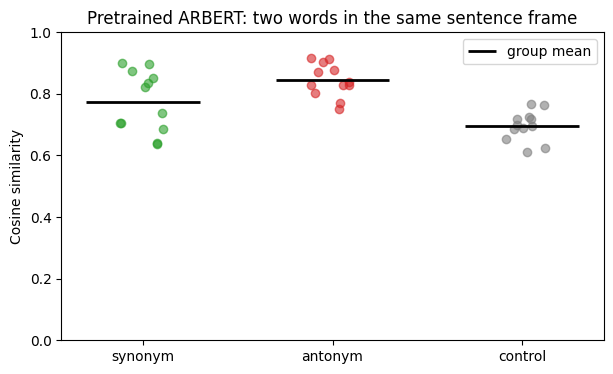

In [28]:
colors = {"synonym": "tab:green", "antonym": "tab:red", "control": "tab:gray"}
rng = np.random.default_rng(0)

fig, ax = plt.subplots(figsize=(7, 4))
for i, rel in enumerate(order):
    vals = comparisons.loc[comparisons["relation"] == rel, "before"]
    ax.scatter(i + rng.uniform(-0.12, 0.12, len(vals)), vals, color=colors[rel], alpha=0.6)
    ax.hlines(vals.mean(), i - 0.3, i + 0.3, color="black", linewidth=2,
              label="group mean" if i == 0 else None)
ax.set_xticks(range(3), order)
ax.set_ylabel("Cosine similarity")
ax.set_ylim(0, 1)
ax.set_title("Pretrained ARBERT: two words in the same sentence frame")
ax.legend()
plt.show()

**Figure 1: Experiment 1.** Each dot represents one comparison, and the black line shows the mean cosine similarity for each group. The control group provides a baseline using word pairs that are neither synonyms nor antonyms.

The antonym group has the highest mean similarity (0.8443), followed by the synonym group (0.7746). Then the control group (0.6962).
The synonym scores also show greater variability (STD = 0.0994) than the antonym scores (STD = 0.0537).

## 8. Experiment 2: Word Families & Sentence Frames → Extract Contextual Embeddings using ARBERT → Calculate Cosine Similarity → Compare Reference, Synonym, Antonym, and Control Words → Analyze Changes Across Word Families

Experiment 2 makes the comparison fairer by using the same sentence frames for three types of word pairs.

Each family contains four words: a **reference Word**, a **synonym**, an **antonym**, and an unrelated **control** word. We place each word in the same three sentence frames and compare its representation with the reference's representation.



### 8.1 Word-Pair Similarity with Matched Contexts

In [29]:
## uses 9 word families.
import re

roles = ["reference", "synonym", "antonym", "control"]

families = {
    # adjective families: the frame has a noun that fits all four adjectives
    "sadness":        {"pos": "adjective", "reference": "حزين",   "synonym": "كئيب",    "antonym": "سعيد",  "control": "مشهور",
                    "frames": ["هذا شخص {}.", "الطفل {} جدا.", "قال الجميع إن الرجل {}."]},

    "temperature": {"pos": "adjective", "reference": "حار",    "synonym": "ساخن",   "antonym": "بارد",  "control": "قديم",
                    "frames": ["هذا ماء {}.", "الشاي {} جدا.", "قال الجميع إن الحساء {}."]},

    "difficulty":  {"pos": "adjective", "reference": "سهل",    "synonym": "بسيط",   "antonym": "صعب",   "control": "مهم",
                    "frames": ["هذا سؤال {}.", "الامتحان {} جدا.", "قال الجميع إن التمرين {}."]},

    "age":         {"pos": "adjective", "reference": "قديم",   "synonym": "عتيق",   "antonym": "جديد",  "control": "مفيد",
                    "frames": ["هذا كتاب {}.", "الكرسي {} جدا.", "قال الجميع إن الجدار {}."]},

    "courage":     {"pos": "adjective", "reference": "شجاع",   "synonym": "جريء",   "antonym": "جبان",  "control": "مبتسم",
                    "frames": ["هذا جندي {}.", "الطفل {} جدا.", "قال الجميع إن الرجل {}."]},

    # noun families: the frame has a preposition or a verb that fits all four nouns
    "love":         {"pos": "noun", "reference": "الحب",  "synonym": "المودة", "antonym": "الكراهية", "control": "المطر",
                    "frames": ["تحدث الرئيس عن {} أمام الجميع.", "قرأ الطلاب عن {} في الكتاب.", "كتب الصحفي عن {} في مقاله."]},

    "pain":     {"pos": "noun", "reference": "الألم", "synonym": "الوجع",  "antonym": "الراحة",  "control": "الحديقة",
                    "frames": ["تحدث شخص عن {} أمام الجمهور.", "قرأ الناس عن {} في الصحيفة.", "كتب عن {} في دفتره."]},

    "light":       {"pos": "noun", "reference": "النور",  "synonym": "الضوء",  "antonym": "الظلام", "control": "الكتاب",
                    "frames": ["تحدث الطلاب عن {} أمام المعلم.", "قرأ شخص عن {} في الصحيفة.", "كتب الجميع عن {} في التقرير."]},

    "hope":        {"pos": "noun", "reference": "الأمل",  "synonym": "الرجاء", "antonym": "اليأس",  "control": "النهر",
                    "frames": ["تحدث فتى عن {} أمام الفصل.", "قرأ رجل عن {} في المجلة.", "كتب عن {} في رسالته."]},
}


def has_word_once(sentence, word):
    return len(re.findall(rf"(?<![\u0621-\u064A]){re.escape(word)}(?![\u0621-\u064A])", sentence)) == 1

for fam, spec in families.items():
    assert len(spec["frames"]) == 3
    for frame in spec["frames"]:
        assert frame.count("{}") == 1, (fam, frame)
        for role in roles:
            assert has_word_once(frame.format(spec[role]), spec[role]), (fam, frame, role)

rows = []
for fam, spec in families.items():
    for frame_id, frame in enumerate(spec["frames"]):
        for relation in order:
            reference, partner = spec["reference"], spec[relation]
            rows.append({"family": fam, "pos": spec["pos"], "relation": relation, "frame_id": frame_id,
                         "reference": reference, "partner": partner, "pair": f"{reference} – {partner}",
                         "sentence1": frame.format(reference), "sentence2": frame.format(partner)})
family_results = pd.DataFrame(rows)

print(family_results.groupby("relation").agg(pairs=("pair", "nunique"), comparisons=("pair", "size")).reindex(order))
family_results[["family", "relation", "sentence1", "sentence2"]].iloc[[0, 1, 2, 27, 28, 29]]

          pairs  comparisons
relation                    
synonym       9           27
antonym       9           27
control       9           27


,family,relation,sentence1,sentence2
0,sadness,synonym,هذا شخص حزين.,هذا شخص كئيب.
1,sadness,antonym,هذا شخص حزين.,هذا شخص سعيد.
2,sadness,control,هذا شخص حزين.,هذا شخص مشهور.
27,age,synonym,هذا كتاب قديم.,هذا كتاب عتيق.
28,age,antonym,هذا كتاب قديم.,هذا كتاب جديد.
29,age,control,هذا كتاب قديم.,هذا كتاب مفيد.


### 8.2. Baseline: Pretrained ARBERT

We extract a vector for each target word in each sentence frame with the pretrained model, and we store the vectors in a dictionary so we can reuse them. Then we calculate the cosine similarity between the reference word and its synonym, antonym, control word in the same frame.

In [30]:
def cos_np(a, b):
    return float(a @ b / (np.linalg.norm(a) * np.linalg.norm(b)))

vectors = {}   # (stage, family, frame_id, role) -> vector

def extract_vectors(stage, encoder):
    # one vector for every word in every frame of every family
    for fam, spec in families.items():
        for frame_id, frame in enumerate(spec["frames"]):
            for role in roles:
                word = spec[role]
                vectors[(stage, fam, frame_id, role)] = np.asarray(
                    get_word_embedding(frame.format(word), word, encoder))

def add_similarity(stage):
    # cosine similarity between the reference and its partner in the same frame
    family_results[stage] = [cos_np(vectors[(stage, r.family, r.frame_id, "reference")],
                                    vectors[(stage, r.family, r.frame_id, r.relation)])
                             for r in family_results.itertuples()]

extract_vectors("before", model)
add_similarity("before")

print("Number of vectors:", len(vectors))
family_results.groupby("relation")["before"].agg(["count", "mean", "std", "min", "max"]).reindex(order).round(4)

Number of vectors: 108


,count,mean,std,min,max
relation,,,,,
synonym,27,0.8240,0.0721,0.6411,0.9037
antonym,27,0.8258,0.0673,0.6767,0.9123
control,27,0.6772,0.0648,0.5322,0.8132


##9.Fine-Tuning ARBERT on Arabic-NLi-Pair-Class Datasets

We fine-tune ARBERT on Arabic NLI dataset to classify sentence pairs as entailment, neutral, or contradiction. This lets us study how the representations change when the model is trained on a task where contradiction matters.



###9.1. Maximum Sequence Length and Training Data

In [31]:
# Check sentence pair lengths to help choose a suitable max_length.
sample = ds["train"].shuffle(seed=SEED).select(range(1000))
pair_lengths = np.array([len(tokenizer(p, h)["input_ids"])
                         for p, h in zip(sample["premise"], sample["hypothesis"])])

print("Mean:", round(pair_lengths.mean(), 1),
      "| 95th percentile:", int(np.percentile(pair_lengths, 95)),
      "| Max:", pair_lengths.max())
for limit in [64, 96, 128]:
    print(f"Pairs longer than {limit} tokens: {np.mean(pair_lengths > limit) * 100:.2f}%")

Mean: 24.9 | 95th percentile: 48 | Max: 96
Pairs longer than 64 tokens: 1.40%
Pairs longer than 96 tokens: 0.00%
Pairs longer than 128 tokens: 0.00%


In [32]:
# Tokenize the sentence pairs and prepare the datasets.
MAX_LENGTH = 96

def tokenize_batch(batch):
    return tokenizer(batch["premise"],batch["hypothesis"],truncation=True,max_length=MAX_LENGTH)

text_cols = ["premise", "hypothesis"]
train_small = ds["train"].shuffle(seed=SEED).select(range(10_000)).map(tokenize_batch, batched=True, remove_columns=text_cols)
val_small   = ds["validation"].shuffle(seed=SEED).select(range(2_000)).map(tokenize_batch, batched=True, remove_columns=text_cols)
test_set    = ds["test"].map(tokenize_batch, batched=True, remove_columns=text_cols)

print(train_small)

Map:   0%|          | 0/10000 [00:00<?, ? examples/s]

Map:   0%|          | 0/2000 [00:00<?, ? examples/s]

Map:   0%|          | 0/19656 [00:00<?, ? examples/s]

Dataset({
    features: ['label', 'input_ids', 'token_type_ids', 'attention_mask'],
    num_rows: 10000
})


We use a random sample of 10,000 pairs for training and 2,000 for validation, because training on all 942k pairs would take too long on a T4 GPU.

The average length is 24.9 tokens, and 95% of the pairs are 48 tokens. Only 1.4% are longer than 64 tokens, and none are longer than 96. So, we use `MAX_LENGTH = 96` to keep almost all pairs from being cut.




###9.2. Training and Checkpoint Selection

We train the model for 3 epochs using a learning rate of 2e-5 and a batch size of 8. After each epoch, we evaluate the model on the validation set and save the checkpoint with the lowest validation loss.


In [33]:
set_seed(SEED)
id2label = dict(enumerate(label_names))
label2id = {name: i for i, name in id2label.items()}

# Load ARBERT with a three-class classification head
nli_model = AutoModelForSequenceClassification.from_pretrained(
    "UBC-NLP/ARBERT", num_labels=3, id2label=id2label, label2id=label2id
).to(device)

BATCH_SIZE = 8
EPOCHS = 3
LEARNING_RATE = 2e-5
SAVE_DIR = "arbert_nli_best"

data_collator = DataCollatorWithPadding(tokenizer)
train_loader = DataLoader(train_small, batch_size=BATCH_SIZE, shuffle=True,  collate_fn=data_collator)
val_loader   = DataLoader(val_small,   batch_size=32,         shuffle=False, collate_fn=data_collator)
test_loader  = DataLoader(test_set,    batch_size=64,         shuffle=False, collate_fn=data_collator)

optimizer = AdamW(nli_model.parameters(), lr=LEARNING_RATE)
total_steps = len(train_loader) * EPOCHS
scheduler = get_linear_schedule_with_warmup(optimizer, int(0.1 * total_steps), total_steps)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: UBC-NLP/ARBERT
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider 

In [34]:
def evaluate(model_to_eval, loader):
    model_to_eval.eval()
    loss_sum, preds, labels = 0.0, [], []
    with torch.no_grad():
        for batch in loader:
            batch = {k: v.to(device) for k, v in batch.items()}
            out = model_to_eval(**batch)
            loss_sum += out.loss.item() * batch["labels"].size(0)
            preds += out.logits.argmax(dim=-1).tolist()
            labels += batch["labels"].tolist()
    metrics = {"loss": loss_sum / len(labels),
               "accuracy": accuracy_score(labels, preds),
               "macro_f1": f1_score(labels, preds, average="macro")}
    return metrics, preds, labels

In [35]:
history = []
best_val_loss, best_epoch = float("inf"), None

for epoch in range(1, EPOCHS + 1):
    nli_model.train()
    train_loss = 0.0
    for batch in tqdm(train_loader, desc=f"Epoch {epoch}/{EPOCHS}"):
        batch = {k: v.to(device) for k, v in batch.items()}
        loss = nli_model(**batch).loss
        loss.backward()
        torch.nn.utils.clip_grad_norm_(nli_model.parameters(), 1.0)
        optimizer.step()
        scheduler.step()
        optimizer.zero_grad()
        train_loss += loss.item() * batch["labels"].size(0)

    # Evaluate after each epoch using the validation data
    val_metrics, _, _ = evaluate(nli_model, val_loader)
    history.append({"epoch": epoch, "train_loss": train_loss / len(train_loader.dataset),
                    **{f"val_{k}": v for k, v in val_metrics.items()}})

    # Save the model when the validation loss becomes lower
    if val_metrics["loss"] < best_val_loss:
        best_val_loss, best_epoch = val_metrics["loss"], epoch
        nli_model.save_pretrained(SAVE_DIR)
        tokenizer.save_pretrained(SAVE_DIR)

pd.DataFrame(history).round(4)

Epoch 1/3:   0%|          | 0/1250 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Epoch 2/3:   0%|          | 0/1250 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Epoch 3/3:   0%|          | 0/1250 [00:00<?, ?it/s]

,epoch,train_loss,val_loss,val_accuracy,val_macro_f1
0,1,0.8813,0.7922,0.6645,0.6409
1,2,0.5416,0.7447,0.7235,0.7217
2,3,0.3139,1.2266,0.7340,0.7328


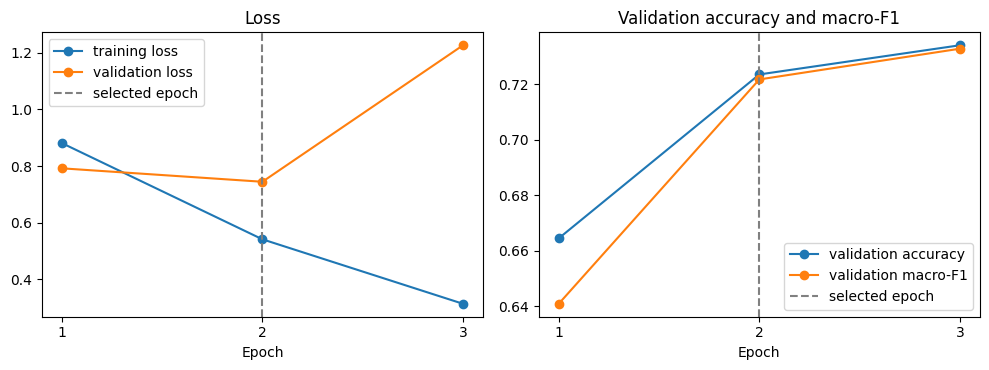

Selected epoch (lowest validation loss): 2
Epoch with the highest validation accuracy: 3


,epoch,train_loss,val_loss,val_accuracy,val_macro_f1,gap (val loss − train loss)
0,1,0.8813,0.7922,0.6645,0.6409,-0.0891
1,2,0.5416,0.7447,0.7235,0.7217,0.2031
2,3,0.3139,1.2266,0.7340,0.7328,0.9127


In [36]:
hist = pd.DataFrame(history)
hist["gap (val loss − train loss)"] = hist["val_loss"] - hist["train_loss"]

fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
axes[0].plot(hist["epoch"], hist["train_loss"], marker="o", label="training loss")
axes[0].plot(hist["epoch"], hist["val_loss"], marker="o", label="validation loss")
axes[0].set_title("Loss")
axes[1].plot(hist["epoch"], hist["val_accuracy"], marker="o", label="validation accuracy")
axes[1].plot(hist["epoch"], hist["val_macro_f1"], marker="o", label="validation macro-F1")
axes[1].set_title("Validation accuracy and macro-F1")
for ax in axes:
    ax.axvline(best_epoch, color="gray", linestyle="--", label="selected epoch")
    ax.set_xticks(hist["epoch"])
    ax.set_xlabel("Epoch")
    ax.legend()
plt.tight_layout()
plt.show()

epoch_by_accuracy = int(hist.loc[hist["val_accuracy"].idxmax(), "epoch"])
print("Selected epoch (lowest validation loss):", best_epoch)
print("Epoch with the highest validation accuracy:", epoch_by_accuracy)
hist.round(4)

Training loss decreased across all three epochs (0.8813, 0.5416, 0.3139), while validation loss decreased in the first two epochs (0.792, 0.7447). Validation accuracy and macro-F1 also improved (0.7235 and 0.7217) at epoch 2, then (0.7340 and 0.7328) at epoch 3.

The increase in validation loss, while training loss continued to decrease, points to signs of overfitting in epoch 3.

Therefore, we selected epoch 2, which achieved the lowest validation loss (0.7447), rather than epoch 3, which achieved the highest validation accuracy and macro-F1.

In [37]:
# load the selected checkpoint
nli_model = AutoModelForSequenceClassification.from_pretrained(SAVE_DIR).to(device).eval()
print("Selected epoch:", best_epoch, "| validation loss:", round(best_val_loss, 4), "| saved in:", SAVE_DIR)

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Selected epoch: 2 | validation loss: 0.7447 | saved in: arbert_nli_best


###9.3. Arabic-NLi-Pair-Class Datasets Test Evaluation

In [38]:
test_metrics, test_preds, test_labels = evaluate(nli_model, test_loader)
print({k: round(v, 4) for k, v in test_metrics.items()})
print()
print(classification_report(test_labels, test_preds, target_names=label_names, digits=4))

{'loss': 0.6934, 'accuracy': 0.7407, 'macro_f1': 0.7408}

               precision    recall  f1-score   support

   entailment     0.7841    0.7747    0.7794      6831
      neutral     0.6590    0.7484    0.7009      6348
contradiction     0.7927    0.6974    0.7420      6477

     accuracy                         0.7407     19656
    macro avg     0.7453    0.7402    0.7408     19656
 weighted avg     0.7466    0.7407    0.7417     19656



The model achieved 74.07% accuracy and 0.7408 macro-F1 on the test set, with a loss of 0.6934.

The classes: "entailment" achieved an F1-score of 0.7794, followed by "contradiction" at 0.7420 and "neutral" at 0.7009.
Neutral had the lowest precision (0.6590), while contradiction had the lowest recall (0.6974).

These results show that the model handled the three NLI classes on unseen data.

## 10. Before vs After Fine-Tuning

 Experiment 1: We compare 36 word-pair comparisons (12 word pairs × 3 sentence frames) before and after fine-tuning to measure how fine-tuning changes their cosine similarity.

In [39]:
# Calculate similarity using the fine-tuned encoder
comparisons["after"] = [cosine(r.sentence1, r.word1, r.sentence2, r.word2, nli_model.base_model)
                        for r in comparisons.itertuples()]
# Calculate the change in similarity
comparisons["change"] = comparisons["after"] - comparisons["before"]

comparisons.groupby("relation")[["before", "after", "change"]].mean().reindex(order).round(4)

,before,after,change
relation,,,
synonym,0.7746,0.8221,0.0475
antonym,0.8443,0.7561,-0.0882
control,0.6962,0.5490,-0.1472


In [40]:
# Calculate average similarity for each word pair across its 3 frames
#the Mean Shows the overall average similarity.
pair_table = (comparisons.groupby(["relation", "pair"])[["before", "after"]].mean()
              .assign(change=lambda d: d["after"] - d["before"])
              .reindex(order, level=0)
              .round(4))
display(pair_table)

# Calculate mean cosine similarity for each word pair across 3 sentence frames.
# The median is less sensitive to unusually large or small changes than the mean.
print("Median change per relation (over the 4 word pairs):")
print(pair_table.groupby("relation")["change"].median().reindex(order).round(4))

before   after  change
relation pair                                   
synonym  الحب – المودة    0.6771  0.7111  0.0340
         جميل – حسن       0.6937  0.7741  0.0803
         سعيد – مسرور     0.8909  0.9167  0.0257
         قوي – متين       0.8367  0.8865  0.0498
antonym  الحب – الكراهية  0.7753  0.6940 -0.0813
         سعيد – حزين      0.8288  0.7339 -0.0948
         طويل – قصير      0.9116  0.7469 -0.1646
         قوي – ضعيف       0.8615  0.8495 -0.0119
control  الحب – المطر     0.6898  0.5766 -0.1132
         سريع – أزرق      0.6973  0.6820 -0.0153
         سعيد – طويل      0.6454  0.3278 -0.3176
         قوي – هادئ       0.7523  0.6094 -0.1429

Median change per relation (over the 4 word pairs):
relation
synonym    0.0419
antonym   -0.0880
control   -0.1280
Name: change, dtype: float64


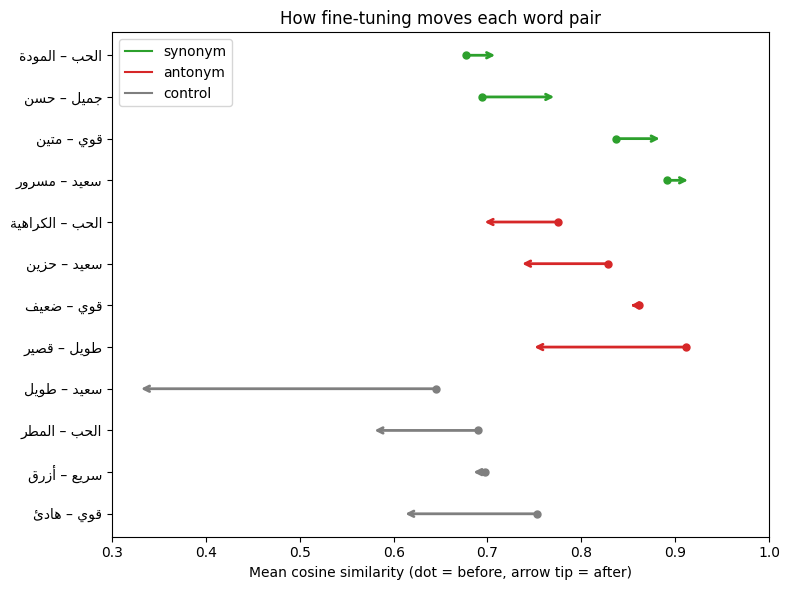

In [41]:
# Calculate mean similarity before and after fine-tuning for each pair
pair_means = comparisons.groupby(["relation", "pair"])[["before", "after"]].mean().reset_index()
pair_means["rank"] = pair_means["relation"].map({r: i for i, r in enumerate(order)})
pair_means = pair_means.sort_values(["rank", "before"]).reset_index(drop=True)

fig, ax = plt.subplots(figsize=(8, 6))
for y, row in pair_means.iterrows():
    ax.scatter(row["before"], y, color=colors[row["relation"]], s=25)
    ax.annotate("", xy=(row["after"], y), xytext=(row["before"], y),
                arrowprops=dict(arrowstyle="->", color=colors[row["relation"]], lw=2))
for rel in order:
    ax.plot([], [], color=colors[rel], label=rel)
ax.set_yticks(range(len(pair_means)), [ar(x) for x in pair_means["pair"]])
ax.invert_yaxis()
ax.set_xlim(0.3, 1.0)
ax.set_xlabel("Mean cosine similarity (dot = before, arrow tip = after)")
ax.set_title("How fine-tuning moves each word pair")
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

**Figure 2: Experiment 1:** Each arrow represents the mean similarity of a word pair across three sentence frames. Right-pointing arrows indicate increased similarity after fine-tuning, while left-pointing arrows indicate decreased similarity.

 For example, similarity increased for the synonym pair جميل–حسن (0.6937 → 0.7741), while it decreased for the antonym pairs (0.7753 → 0.6940)الحب–الكراهية and طويل-قصير(0.9116 → 0.7469).  

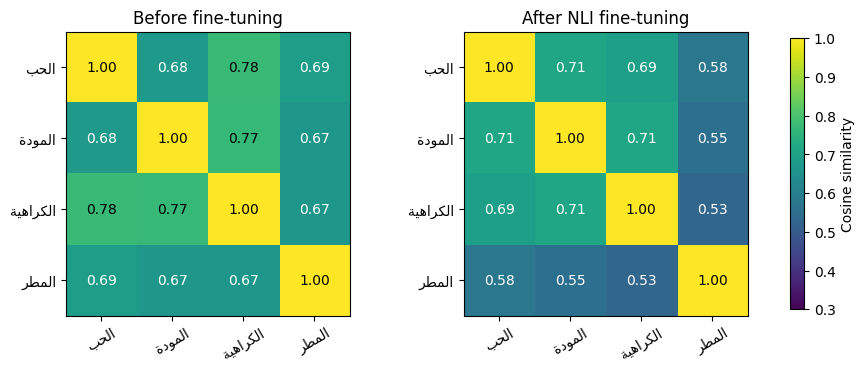

In [42]:
selected_words = ["الحب", "المودة", "الكراهية", "المطر"]

def similarity_matrix(encoder):
    vectors = {w: [get_word_embedding(f.format(w), w, encoder) for f in SHARED_FRAMES] for w in selected_words}
    matrix = np.zeros((4, 4))
    for i, a in enumerate(selected_words):
        for j, b in enumerate(selected_words):
            matrix[i, j] = np.mean([F.cosine_similarity(x, y, dim=0).item()
                                    for x, y in zip(vectors[a], vectors[b])])
    return matrix

fig, axes = plt.subplots(1, 2, figsize=(11, 4.4))
fig.subplots_adjust(wspace=0.4)
for ax, encoder, title in zip(axes, [model, nli_model.base_model],
                              ["Before fine-tuning", "After NLI fine-tuning"]):
    matrix = similarity_matrix(encoder)
    image = ax.imshow(matrix, vmin=0.3, vmax=1.0, cmap="viridis")
    ax.set_xticks(range(4), [ar(w) for w in selected_words], rotation=30)
    ax.set_yticks(range(4), [ar(w) for w in selected_words])
    ax.set_title(title)
    for i in range(4):
        for j in range(4):
            ax.text(j, i, f"{matrix[i, j]:.2f}", ha="center", va="center",
                    color="white" if matrix[i, j] < 0.75 else "black")
fig.colorbar(image, ax=axes, shrink=0.8, label="Cosine similarity")
plt.show()

**Figure 3: Experiment 1:** Heatmaps of mean cosine similarity for the reference word الحب and its synonym المودة, antonym الكراهية, and control word المطر, before and after NLI dataset fine-tuning. All four words are evaluated in the same three sentence frames

The heatmaps show that fine-tuning changes the pairwise similarities in  selected word set. Before fine-tuning, the reference word had a similarity of 0.68 with its synonym 0.78 with its antonym and 0.69 with the control word

After fine-tuning, the similarity between reference and antonym decreases from 0.78 to 0.69 while the similarity between reference and control 0.69 to 0.58 and The similarity between antonyms and control also decreased from 0.67 to 0.53.

### 10.1: Summary of Experiment 1

In [43]:
# Calculate mean similarity for each word pair across its three frames.
pair_summary = (
    comparisons.groupby(["relation", "pair"])[["before", "after"]]
    .mean()
    .reset_index()
)

pair_summary["change"] = pair_summary["after"] - pair_summary["before"]

# Summarize the results for each relation.
for relation in order:
    t = pair_summary[pair_summary["relation"] == relation]

    print(f"\n[{relation}]")
    print(f"Before: {t['before'].mean():.4f}")
    print(f"After:  {t['after'].mean():.4f}")
    print(f"Pairs with increased similarity: {(t['change'] > 0).sum()}/4")
    print(f"Pairs with decreased similarity: {(t['change'] < 0).sum()}/4")
    print(f"Median change: {t['change'].median():.4f}")


[synonym]
Before: 0.7746
After:  0.8221
Pairs with increased similarity: 4/4
Pairs with decreased similarity: 0/4
Median change: 0.0419

[antonym]
Before: 0.8443
After:  0.7561
Pairs with increased similarity: 0/4
Pairs with decreased similarity: 4/4
Median change: -0.0881

[control]
Before: 0.6962
After:  0.5490
Pairs with increased similarity: 0/4
Pairs with decreased similarity: 4/4
Median change: -0.1280


Experiment 2: We compare 108 word–frame combinations (9 word families × 4 words × 3 sentence frames) before and after fine-tuning to measure how fine-tuning changes their representations.

In [44]:
extract_vectors("after", nli_model.base_model)
add_similarity("after")
family_results["change"] = family_results["after"] - family_results["before"]

print("Number of vectors:", len(vectors))
family_results.groupby("relation")[["before", "after", "change"]].agg(["mean", "std"]).reindex(order).round(4)

Number of vectors: 216


before           after          change        
            mean     std    mean     std    mean     std
relation                                                
synonym   0.8240  0.0721  0.7862  0.0696 -0.0378  0.0495
antonym   0.8258  0.0673  0.7365  0.0740 -0.0893  0.0509
control   0.6772  0.0648  0.5588  0.0868 -0.1183  0.1081

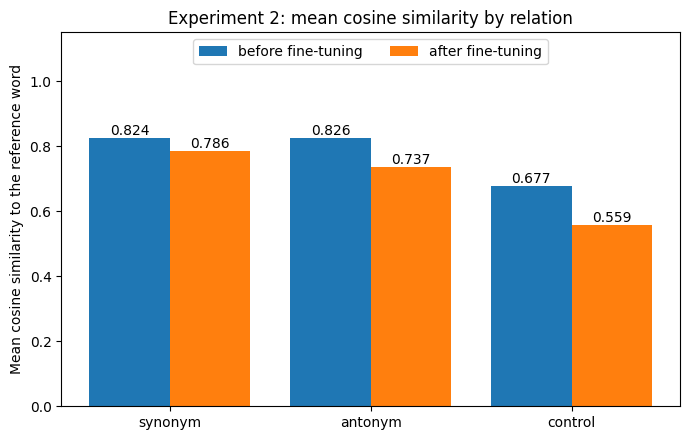

In [45]:
# Each mean is calculated across 27 comparisons (9 families × 3 sentence frames).
means = family_results.groupby("relation")[["before", "after"]].mean().reindex(order)
x = np.arange(len(order))

fig, ax = plt.subplots(figsize=(7, 4.5))
bars_before = ax.bar(x - 0.2, means["before"], width=0.4, label="before fine-tuning", color="tab:blue")
bars_after = ax.bar(x + 0.2, means["after"], width=0.4, label="after fine-tuning", color="tab:orange")
ax.bar_label(bars_before, fmt="%.3f")
ax.bar_label(bars_after, fmt="%.3f")
ax.set_xticks(x, order)
ax.set_ylabel("Mean cosine similarity to the reference word")
ax.set_ylim(0, 1.15)
ax.set_title("Experiment 2: mean cosine similarity by relation")
ax.legend(loc="upper center", ncol=2)
plt.tight_layout()
plt.show()

**Figure 1: Experiment 2:** Shows the mean cosine similarity between the reference word and its synonym, antonym, and control word before and after NLI fine-tuning.


Before fine-tuning, synonyms and antonyms had similarity scores (0.824 and 0.826), while controls had a lower score (0.677). After fine-tuning, all three scores decreased: synonyms to 0.786, antonyms to 0.737, and controls to 0.559.


In [46]:
family_table = pd.concat(
    {stage: family_results.pivot_table(index="family", columns="relation", values=stage).reindex(columns=order)
     for stage in ["before", "after"]}, axis=1).round(3)
family_table

before                   after                
relation    synonym antonym control synonym antonym control
family                                                     
age           0.844   0.815   0.683   0.758   0.712   0.592
courage       0.884   0.861   0.620   0.858   0.746   0.722
difficulty    0.833   0.899   0.764   0.722   0.745   0.584
hope          0.799   0.778   0.707   0.771   0.715   0.450
light         0.860   0.858   0.614   0.822   0.809   0.565
love          0.664   0.748   0.693   0.682   0.685   0.558
pain          0.864   0.728   0.625   0.870   0.630   0.438
sadness       0.793   0.839   0.651   0.781   0.726   0.582
temperature   0.874   0.906   0.738   0.813   0.860   0.538

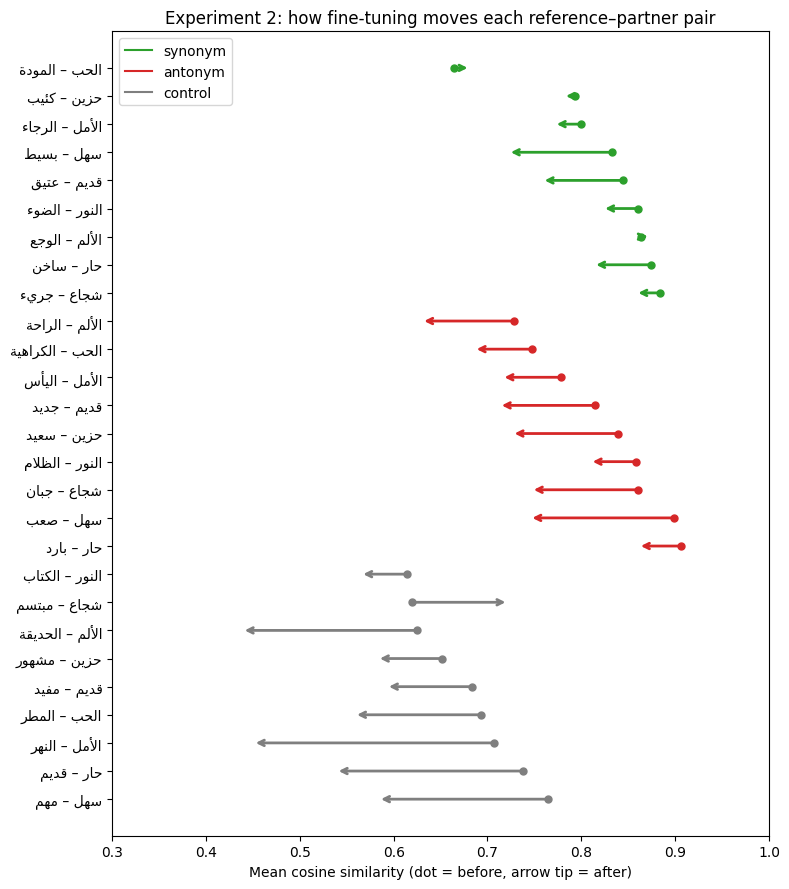

In [47]:
fam_pairs = family_results.groupby(["relation", "pair"])[["before", "after"]].mean().reset_index()
fam_pairs["rank"] = fam_pairs["relation"].map({r: i for i, r in enumerate(order)})
fam_pairs = fam_pairs.sort_values(["rank", "before"]).reset_index(drop=True)

fig, ax = plt.subplots(figsize=(8, 9))
for y, row in fam_pairs.iterrows():
    ax.scatter(row["before"], y, color=colors[row["relation"]], s=25)
    ax.annotate("", xy=(row["after"], y), xytext=(row["before"], y),
                arrowprops=dict(arrowstyle="->", color=colors[row["relation"]], lw=2))
for rel in order:
    ax.plot([], [], color=colors[rel], label=rel)
ax.set_yticks(range(len(fam_pairs)), [ar(x) for x in fam_pairs["pair"]])
ax.invert_yaxis()
ax.set_xlim(0.3, 1.0)
ax.set_xlabel("Mean cosine similarity (dot = before, arrow tip = after)")
ax.set_title("Experiment 2: how fine-tuning moves each reference–partner pair")
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

**Figure 2: Experiment 2:**  Each row represents one word pair, averaged across the three sentence frames. The dot shows cosine similarity before fine-tuning, and the arrow shows its change after fine-tuning.


For example, all these pairs are decreases, not increases: the synonym pairs سهل–بسيط (0.833 → 0.722) and قديم–عتيق (0.844 → 0.758), and the antonym pairs حار–بارد (0.906 → 0.860) and سهل–صعب (0.899 → 0.745).
These examples show that fine-tuning did not affect every pair by the same amount.


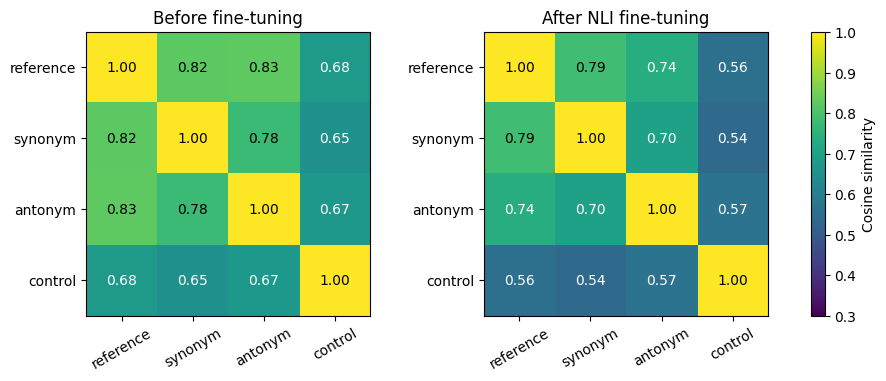

In [48]:
def role_matrix(stage):
    matrix = np.zeros((4, 4))
    for i, a in enumerate(roles):
        for j, b in enumerate(roles):
            matrix[i, j] = np.mean([cos_np(vectors[(stage, fam, f, a)], vectors[(stage, fam, f, b)])
                                    for fam in families for f in range(3)])
    return matrix

fig, axes = plt.subplots(1, 2, figsize=(11, 4.6))
fig.subplots_adjust(wspace=0.4)
for ax, stage, title in zip(axes, ["before", "after"], ["Before fine-tuning", "After NLI fine-tuning"]):
    matrix = role_matrix(stage)
    image = ax.imshow(matrix, vmin=0.3, vmax=1.0, cmap="viridis")
    ax.set_xticks(range(4), roles, rotation=30)
    ax.set_yticks(range(4), roles)
    ax.set_title(title)
    for i in range(4):
        for j in range(4):
            ax.text(j, i, f"{matrix[i, j]:.2f}", ha="center", va="center",
                    color="white" if matrix[i, j] < 0.75 else "black")
fig.colorbar(image, ax=axes, shrink=0.8, label="Cosine similarity")
plt.show()

**Figure 3: Experiment 2:** Heatmaps of mean cosine similarity
for the reference word and its synonym, antonym, and control word, before and after NLI dataset fine-tuning for Experiment 2.

Before fine-tuning, the reference word had a similarity score of 0.82 with synonyms and 0.83 with antonyms, while control words scored 0.68.

After fine-tuning, similarity decreased from 0.83 to 0.74 for the reference–antonym pair, from 0.68 to 0.56 for the reference–control pair, and from 0.82 to 0.79 for the reference–synonym pair.


###10.2: Summary of Experiment 2

In [49]:
# Count families showing each pattern, using the average similarity across three frames per family.
fam_rel = family_results.groupby(["family", "relation"])[["before", "after"]].mean().reset_index()

for stage in ["before", "after"]:
    t = fam_rel.pivot(index="family", columns="relation", values=stage)
    n = len(t)
    print(f"[{stage}] mean similarity to the reference: " + ", ".join(f"{r} {t[r].mean():.3f}" for r in order))
    print(f"[{stage}] families where antonym > synonym: {(t['antonym'] > t['synonym']).sum()}/{n}"
          f" | antonym > control: {(t['antonym'] > t['control']).sum()}/{n}"
          f" | synonym > control: {(t['synonym'] > t['control']).sum()}/{n}")
    print()

change = fam_rel.assign(change=fam_rel["after"] - fam_rel["before"]).pivot(index="family", columns="relation", values="change")
for r in order:
    print(f"Families where the {r} partner became more similar after fine-tuning: {(change[r] > 0).sum()}/{len(change)}")

[before] mean similarity to the reference: synonym 0.824, antonym 0.826, control 0.677
[before] families where antonym > synonym: 4/9 | antonym > control: 9/9 | synonym > control: 8/9

[after] mean similarity to the reference: synonym 0.786, antonym 0.737, control 0.559
[after] families where antonym > synonym: 3/9 | antonym > control: 9/9 | synonym > control: 9/9

Families where the synonym partner became more similar after fine-tuning: 2/9
Families where the antonym partner became more similar after fine-tuning: 0/9
Families where the control partner became more similar after fine-tuning: 1/9


## 11.Gap-to-Control Analysis

Fine-tuning may change all similarities, including unrelated control words. To account for this, we compare each relation with its family control using three gaps: antonym − control, synonym − control, and antonym − synonym. We use Experiment 2 because all words share the same sentence frames.


A positive gap means the first word is more similar to the reference than the second. We compare these gaps before and after fine-tuning and count how many of the 9 families show each pattern.

In [50]:
# with the family as the unit (n = 9). Each value is the mean of the three frames of one family.
fam_wide = {stage: fam_rel.pivot(index="family", columns="relation", values=stage)[order]
            for stage in ["before", "after"]}
contrasts = [("antonym", "control"), ("synonym", "control"), ("antonym", "synonym")]

def gap_summary(families_to_use):
    rows = []
    for a, b in contrasts:
        before = fam_wide["before"].loc[families_to_use, a] - fam_wide["before"].loc[families_to_use, b]
        after = fam_wide["after"].loc[families_to_use, a] - fam_wide["after"].loc[families_to_use, b]
        rows.append({"gap": f"{a} − {b}", "before": before.mean(), "after": after.mean(),
                     "change": (after - before).mean(),
                     "families with gap > 0 (before)": int((before > 0).sum()),
                     "families with gap > 0 (after)": int((after > 0).sum()),
                     "families where the gap grew": int((after > before).sum())})
    return pd.DataFrame(rows)

all_families = list(fam_wide["before"].index)
gap_table = gap_summary(all_families)
print(f"All {len(all_families)} families:")
display(gap_table.round(3))

All 9 families:


,gap,before,after,change,families with gap > 0 (before),families with gap > 0 (after),families where the gap grew
0,antonym − control,0.149,0.178,0.029,9,9,6
1,synonym − control,0.147,0.227,0.081,8,9,8
2,antonym − synonym,0.002,-0.050,-0.052,4,3,1


### 12. Same Frame vs Different Frame

We test whether antonym similarity is caused by shared sentence frames by comparing words across different frames.

If antonyms are similar only because they share a frame, their similarity should decrease to the control level in different frames. If it remains higher, this suggests that shared sentence frames may not fully explain the observed similarity.

In [51]:
partner_roles = ["reference", "synonym", "antonym", "control"]
rows = []
for stage in ["before", "after"]:
    for fam in families:
        for role in partner_roles:
            for i in range(3):
                for j in range(3):
                    if role == "reference" and i == j:
                        continue
                    rows.append({"stage": stage, "family": fam, "partner": role,
                                 "frame": "same frame" if i == j else "different frame",
                                 "cosine": cos_np(vectors[(stage, fam, i, "reference")], vectors[(stage, fam, j, role)])})
frame_word = pd.DataFrame(rows)

# one value per family, then the mean over the 9 families
fw_family = frame_word.groupby(["stage", "partner", "frame", "family"])["cosine"].mean().reset_index()
fw_index = pd.MultiIndex.from_product([["before", "after"], partner_roles], names=["stage", "partner"])
frame_word_table = (fw_family.groupby(["stage", "partner", "frame"])["cosine"].mean()
                    .unstack("frame").reindex(fw_index))
frame_word_table["same − different"] = frame_word_table["same frame"] - frame_word_table["different frame"]
display(frame_word_table.round(3))

for stage in ["before", "after"]:
    t = frame_word_table.loc[stage]
    print(f"[{stage}] in a different frame: antonym − control = "
          f"{t.loc['antonym', 'different frame'] - t.loc['control', 'different frame']:+.3f}, "
          f"antonym − synonym = {t.loc['antonym', 'different frame'] - t.loc['synonym', 'different frame']:+.3f}")

frame             different frame  same frame  same − different
stage  partner                                                 
before reference            0.766         NaN               NaN
       synonym              0.636       0.824             0.188
       antonym              0.635       0.826             0.191
       control              0.514       0.677             0.163
after  reference            0.773         NaN               NaN
       synonym              0.627       0.786             0.159
       antonym              0.579       0.737             0.157
       control              0.441       0.559             0.118

[before] in a different frame: antonym − control = +0.121, antonym − synonym = -0.000
[after] in a different frame: antonym − control = +0.138, antonym − synonym = -0.048


##13.Embedding Space Visualization (PCA)

Before PCA, we subtract the mean of the four word vectors in each family and sentence frame to reduce their shared effects.

PCA reduces the 768-dimensional vectors to two dimensions for visualization. The two components retain 15% of the variance, The plot helps us compare the relative positions of the four word roles before and after fine-tuning.









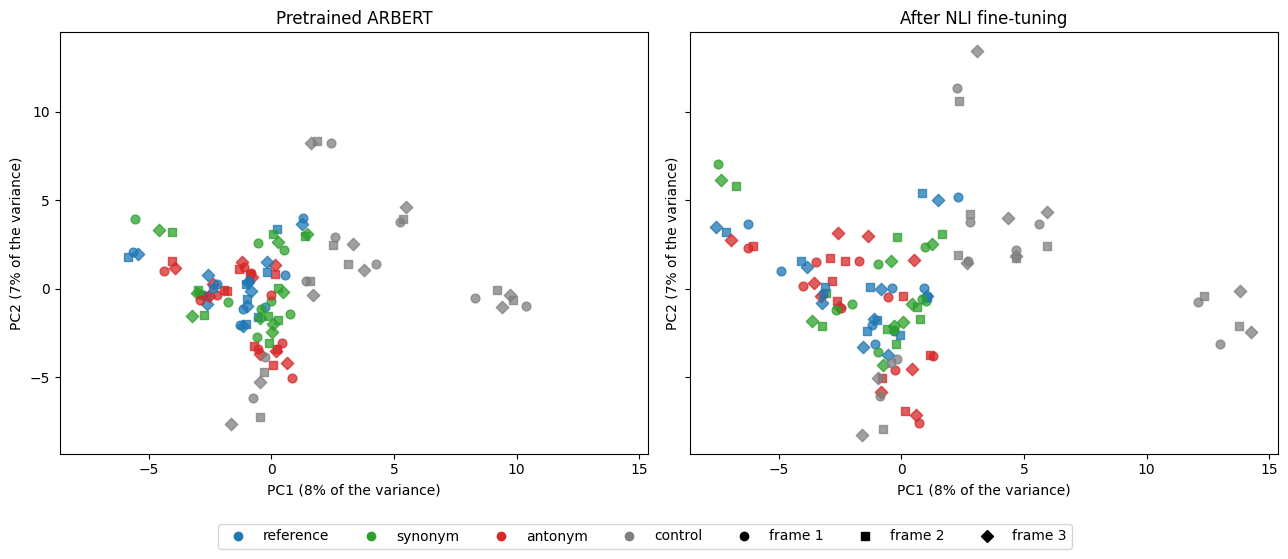

In [52]:
from sklearn.decomposition import PCA

CENTER_BY_FRAME = True    # subtract the mean of the four words that share a family and a frame
role_colors = {"reference": "tab:blue", "synonym": "tab:green", "antonym": "tab:red", "control": "tab:gray"}
frame_markers = ["o", "s", "D"]
keys = [(fam, f, role) for fam in families for f in range(3) for role in roles]

def pca_input(stage):
    X = np.stack([vectors[(stage,) + k] for k in keys])
    if CENTER_BY_FRAME:
        X = X.reshape(-1, len(roles), X.shape[1])
        X = (X - X.mean(axis=1, keepdims=True)).reshape(-1, X.shape[2])
    return X

pca = PCA(n_components=2).fit(np.vstack([pca_input("before"), pca_input("after")]))
points = {stage: pca.transform(pca_input(stage)) for stage in ["before", "after"]}

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5), sharex=True, sharey=True)
for ax, stage, title in zip(axes, ["before", "after"], ["Pretrained ARBERT", "After NLI fine-tuning"]):
    for (fam, f, role), (px, py) in zip(keys, points[stage]):
        ax.scatter(px, py, color=role_colors[role], marker=frame_markers[f], s=40, alpha=0.75)
    ax.set_title(title)
    ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.0%} of the variance)")
    ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.0%} of the variance)")

handles = [plt.Line2D([], [], color=c, marker="o", linestyle="", label=r) for r, c in role_colors.items()]
handles += [plt.Line2D([], [], color="black", marker=m, linestyle="", label=f"frame {i + 1}") for i, m in enumerate(frame_markers)]
fig.legend(handles=handles, loc="lower center", ncol=7, bbox_to_anchor=(0.5, -0.02))
plt.tight_layout(rect=[0, 0.06, 1, 1])
plt.show()

**Figure :** Two-dimensional PCA projection of word representations before and after fine-tuning.

Each panel contains 108 points (9 families × 3 frames × 4 word roles). Colours represent word roles, while marker shapes represent sentence frames.




##14. All the Results


In [53]:
print("Experiment 1 (12 word pairs, 36 comparisons) - mean cosine similarity")
display(comparisons.groupby("relation")[["before", "after"]].mean().reindex(order).round(4))

print("Experiment 2 (9 families, 27 comparisons per relation) - mean cosine similarity")
display(family_results.groupby("relation")[["before", "after"]].mean().reindex(order).round(4))

print("Gap to control (Experiment 2, mean of the 9 families)")
display(gap_table[["gap", "before", "after", "change"]].round(3))

print(f"Checkpoint: epoch {best_epoch} (lowest validation loss) | test accuracy {test_metrics['accuracy']:.4f} | test macro-F1 {test_metrics['macro_f1']:.4f}")

Experiment 1 (12 word pairs, 36 comparisons) - mean cosine similarity


,before,after
relation,,
synonym,0.7746,0.8221
antonym,0.8443,0.7561
control,0.6962,0.5490


Experiment 2 (9 families, 27 comparisons per relation) - mean cosine similarity


,before,after
relation,,
synonym,0.8240,0.7862
antonym,0.8258,0.7365
control,0.6772,0.5588


Gap to control (Experiment 2, mean of the 9 families)


,gap,before,after,change
0,antonym − control,0.149,0.178,0.029
1,synonym − control,0.147,0.227,0.081
2,antonym − synonym,0.002,-0.050,-0.052


Checkpoint: epoch 2 (lowest validation loss) | test accuracy 0.7407 | test macro-F1 0.7408


In [54]:
# Save the results
comparisons.to_csv("word_similarity_results.csv", index=False, encoding="utf-8-sig")
family_results.to_csv("family_similarity_results.csv", index=False, encoding="utf-8-sig")
gap_table.to_csv("gap_to_control_results.csv", index=False, encoding="utf-8-sig")
frame_word_table.reset_index().to_csv("frame_vs_word_results.csv", index=False, encoding="utf-8-sig")

##15. Conclusion
This project examined whether ARBERT places words with opposite meanings close to each other when they appear in similar contexts, and whether NLI dataset fine-tuning changes this similarity.

Before fine-tuning, synonyms and antonyms had almost the same mean cosine similarity in Experiment 2 (0.824 and 0.826). Both were higher than control words (0.677). This shows that words with opposite meanings can have similar representations when they appear in similar sentence frames.

After fine-tuning, similarity decreased for all three groups: synonyms (0.786), antonyms (0.737), and control words (0.559). Antonyms were still more similar to the reference words than control words, even when they appeared in different sentences.


However, the synonym results differed between the two experiments: their similarity increased in Experiment 1 but decreased in Experiment 2. This means the results were different between the two experiments.

In conclusion, ARBERT can place words with opposite meanings close to each other, even after NLI fine-tuning. Fine-tuning changed the similarity between word representations. However, antonyms remained more similar to the reference words than control words after fine-tuning.


Limitations:
- The study included only 9 word families and 3 sentence frames.
- The experiments used ARBERT only, without comparing it with other models.
- Cosine similarity shows how close word representations are, but it cannot explain why they are close.

##16.App

In [1]:
!pip install -q gradio plotly transformers

In [2]:
import gradio as gr
import plotly.express as px
import torch
import transformers

print("Gradio:", gr.__version__)
print("Plotly:", px.__name__)
print("PyTorch:", torch.__version__)
print("Transformers:", transformers.__version__)

print("Environment is ready!")

Gradio: 6.31.0
Plotly: plotly.express
PyTorch: 2.11.0+cu130
Transformers: 5.22.0
Environment is ready!


In [3]:
import os

model_path = "/content/arbert_nli_best"
print(os.listdir(model_path))

['model.safetensors', 'config.json', 'tokenizer.json', 'tokenizer_config.json']


In [4]:
import torch
from transformers import AutoTokenizer, AutoModel

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Original pretrained ARBERT
base_name = "UBC-NLP/ARBERT"

base_tokenizer = AutoTokenizer.from_pretrained(base_name)
base_model = AutoModel.from_pretrained(base_name).to(device)

# Fine-tuned ARBERT
model_path = "/content/arbert_nli_best"

finetuned_tokenizer = AutoTokenizer.from_pretrained(model_path)
finetuned_model = AutoModel.from_pretrained(model_path).to(device)

base_model.eval()
finetuned_model.eval()

print("Both models loaded successfully!")
print("Device:", device)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: UBC-NLP/ARBERT
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.decoder.weight             | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: /content/arbert_nli_best
Key               | Status     |  | 
------------------+------------+--+-
classifier.weight | UNEXPECTED |  | 
classifier.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Both models loaded successfully!
Device: cuda


In [5]:
import torch
import torch.nn.functional as F

def get_word_embedding(sentence, target_word, tokenizer, encoder):
    sentence = sentence.strip()
    target_word = target_word.strip()

    if not sentence or not target_word:
        raise ValueError("أدخلي الجملة والكلمة المستهدفة.")

    # Find the exact word position in the sentence
    start = sentence.find(target_word)

    if start == -1:
        raise ValueError(
            f"الكلمة '{target_word}' غير موجودة في الجملة."
        )

    end = start + len(target_word)

    # Tokenize and obtain character offsets
    encoded = tokenizer(
        sentence,
        return_tensors="pt",
        return_offsets_mapping=True,
        truncation=True,
        max_length=256
    )

    offsets = encoded.pop("offset_mapping")[0].tolist()

    # Identify tokens that overlap with the target word
    token_positions = [
        i for i, (a, b) in enumerate(offsets)
        if a < end and b > start
    ]

    if not token_positions:
        raise ValueError("تعذر تحديد أجزاء الكلمة داخل Tokens.")

    model_inputs = {
        key: value.to(device)
        for key, value in encoded.items()
    }

    encoder.eval()

    with torch.no_grad():
        outputs = encoder(**model_inputs)

    # Mean pooling over the target word's WordPieces
    embedding = outputs.last_hidden_state[
        0, token_positions
    ].mean(dim=0)

    return embedding.detach().float().cpu()

In [6]:
word1 = "سعيد"
sentence1 = "عاد الطفل سعيدًا بعد انتهاء الرحلة."

word2 = "حزين"
sentence2 = "عاد الطفل حزينًا بعد انتهاء الرحلة."

# Pretrained ARBERT
emb1_before = get_word_embedding(
    sentence1, word1, base_tokenizer, base_model
)

emb2_before = get_word_embedding(
    sentence2, word2, base_tokenizer, base_model
)

# Fine-tuned ARBERT
emb1_after = get_word_embedding(
    sentence1, word1, finetuned_tokenizer, finetuned_model
)

emb2_after = get_word_embedding(
    sentence2, word2, finetuned_tokenizer, finetuned_model
)

# Cosine similarity
before_score = F.cosine_similarity(
    emb1_before.unsqueeze(0),
    emb2_before.unsqueeze(0)
).item()

after_score = F.cosine_similarity(
    emb1_after.unsqueeze(0),
    emb2_after.unsqueeze(0)
).item()

print("Pretrained ARBERT:", round(before_score, 4))
print("Fine-tuned ARBERT:", round(after_score, 4))
print("Embedding shape:", emb1_before.shape)

Pretrained ARBERT: 0.8858
Fine-tuned ARBERT: 0.7883
Embedding shape: torch.Size([768])


In [23]:
import gradio as gr
import plotly.graph_objects as go
from plotly.subplots import make_subplots
import torch
import torch.nn.functional as F
import pandas as pd
import numpy as np

from sklearn.decomposition import PCA


# 1. Reference dataset

reference_experiments = [
    # Synonyms
    {
        "word1": "سعيد",
        "word2": "مسرور",
        "relation": "synonym",
        "contexts": [
            ("أنا أشعر بأنني سعيد اليوم", "سعيد",
             "أنا أشعر بأنني مسرور اليوم", "مسرور"),

            ("عاد الطفل سعيدًا إلى المنزل", "سعيدًا",
             "عاد الطفل مسرورًا إلى المنزل", "مسرورًا"),

            ("كان الرجل سعيدًا بالنتيجة", "سعيدًا",
             "كان الرجل مسرورًا بالنتيجة", "مسرورًا")
        ]
    },

    {
        "word1": "قوي",
        "word2": "متين",
        "relation": "synonym",
        "contexts": [
            ("هذا فتى قوي", "قوي",
             "هذا فتى متين", "متين"),

            ("يبدو البناء قويًا", "قويًا",
             "يبدو البناء متينًا", "متينًا"),

            ("نحتاج إلى دليل قوي", "قوي",
             "نحتاج إلى دليل متين", "متين")
        ]
    },

    # Antonyms
    {
        "word1": "سعيد",
        "word2": "حزين",
        "relation": "antonym",
        "contexts": [
            ("أنا أشعر بأنني سعيد اليوم", "سعيد",
             "أنا أشعر بأنني حزين اليوم", "حزين"),

            ("عاد الطفل سعيدًا إلى المنزل", "سعيدًا",
             "عاد الطفل حزينًا إلى المنزل", "حزينًا"),

            ("كان الرجل سعيدًا بالنتيجة", "سعيدًا",
             "كان الرجل حزينًا بالنتيجة", "حزينًا")
        ]
    },

    {
        "word1": "قوي",
        "word2": "ضعيف",
        "relation": "antonym",
        "contexts": [
            ("هذا رجل قوي", "قوي",
             "هذا رجل ضعيف", "ضعيف"),

            ("يبدو الصوت قويًا", "قويًا",
             "يبدو الصوت ضعيفًا", "ضعيفًا"),

            ("كان الدليل قويًا", "قويًا",
             "كان الدليل ضعيفًا", "ضعيفًا")
        ]
    },

    # Unrelated words
    {
        "word1": "سعيد",
        "word2": "طويل",
        "relation": "unrelated",
        "contexts": [
            ("هذا شخص سعيد", "سعيد",
             "هذا شخص طويل", "طويل"),

            ("قابلت رجلًا سعيدًا", "سعيدًا",
             "قابلت رجلًا طويلًا", "طويلًا"),

            ("كان الطفل سعيدًا", "سعيدًا",
             "كان الطفل طويلًا", "طويلًا")
        ]
    },

    {
        "word1": "قوي",
        "word2": "هادئ",
        "relation": "unrelated",
        "contexts": [
            ("هذا فتى قوي", "قوي",
             "هذا فتى هادئ", "هادئ"),

            ("كان الصوت قويًا", "قويًا",
             "كان الصوت هادئًا", "هادئًا"),

            ("وجدت شخصًا قويًا", "قويًا",
             "وجدت شخصًا هادئًا", "هادئًا")
        ]
    }
]


# 2. Build reference embeddings

def build_reference_embeddings(encoder, tokenizer):
    rows = []

    for item in reference_experiments:
        for sentence1, word1, sentence2, word2 in item["contexts"]:

            emb1 = get_word_embedding(sentence1, word1, tokenizer, encoder)

            emb2 = get_word_embedding(sentence2, word2, tokenizer, encoder)

            rows.append({
                "word": word1,
                "relation": item["relation"],
                "embedding": emb1.numpy()
            })

            rows.append({
                "word": word2,
                "relation": item["relation"],
                "embedding": emb2.numpy()
            })

    return pd.DataFrame(rows)


# Extract reference representations from both models

reference_before = build_reference_embeddings(base_model, base_tokenizer)

reference_after = build_reference_embeddings(finetuned_model, finetuned_tokenizer)

print("Before:", reference_before.shape)
print("After:", reference_after.shape)
print("Reference words:", reference_before["word"].nunique())


# 3. Compare two words

def compare_words(word1, sentence1, word2, sentence2, relation):
    if not all([
        word1.strip(),
        sentence1.strip(),
        word2.strip(),
        sentence2.strip()
    ]):
        raise gr.Error("يرجى إدخال الكلمتين والجملتين.")

    word1 = word1.strip()
    word2 = word2.strip()

    # Extract representations before fine-tuning
    emb1_before = get_word_embedding(sentence1, word1, base_tokenizer, base_model)

    emb2_before = get_word_embedding(sentence2, word2, base_tokenizer, base_model)

    # Extract representations after fine-tuning
    emb1_after = get_word_embedding(sentence1, word1, finetuned_tokenizer, finetuned_model)

    emb2_after = get_word_embedding(sentence2, word2, finetuned_tokenizer, finetuned_model)

    # Calculate cosine similarity in the original 768-dimensional space
    before_score = F.cosine_similarity(
        emb1_before.unsqueeze(0),
        emb2_before.unsqueeze(0)
    ).item()

    after_score = F.cosine_similarity(
        emb1_after.unsqueeze(0),
        emb2_after.unsqueeze(0)
    ).item()


    # 4. Create PCA visualization

    fig = make_subplots(
        rows=1,
        cols=2,
        subplot_titles=[
            "Pretrained ARBERT",
            "Fine-tuned ARBERT"
        ]
    )

    model_data = [
        (
            reference_before,
            [emb1_before.numpy(), emb2_before.numpy()],
            1
        ),
        (
            reference_after,
            [emb1_after.numpy(), emb2_after.numpy()],
            2
        )
    ]

    relation_colors = {
        "synonym": "#2E86AB",
        "antonym": "#E76F51",
        "unrelated": "#8A8A8A"
    }

    relation_names = {
        "synonym": "مترادفات",
        "antonym": "متضادات",
        "unrelated": "غير مترابطة"
    }

    for reference_df, user_embeddings, column in model_data:

        reference_vectors = np.stack(
            reference_df["embedding"].to_list()
        )

        user_vectors = np.stack(user_embeddings)

        all_vectors = np.vstack([
            reference_vectors,
            user_vectors
        ])

        # Fit PCA separately for each model
        pca = PCA(n_components=2)
        projected = pca.fit_transform(all_vectors)
        reference_points = projected[:-2]
        user_points = projected[-2:]


        # Plot reference points by relation
        for relation_type in [
            "synonym",
            "antonym",
            "unrelated"
        ]:

            indices = np.where(
                reference_df["relation"].values == relation_type
            )[0]

            fig.add_trace(
                go.Scatter(
                    x=reference_points[indices, 0],
                    y=reference_points[indices, 1],
                    mode="markers",
                    name=relation_names[relation_type],
                    legendgroup=relation_type,
                    showlegend=(column == 1),

                    marker=dict(
                        color=relation_colors[relation_type],
                        size=9,
                        opacity=0.65
                    ),

                    text=reference_df.iloc[indices]["word"],

                    hovertemplate=(
                        "الكلمة: %{text}<br>"
                        + "العلاقة: "
                        + relation_names[relation_type]
                        + "<extra></extra>"
                    )
                ),
                row=1,
                col=column
            )


        # Plot user words
        fig.add_trace(
            go.Scatter(
                x=user_points[:, 0],
                y=user_points[:, 1],
                mode="markers+text",
                name="الكلمات المدخلة",
                legendgroup="user_words",
                showlegend=(column == 1),

                text=[word1, word2],
                textposition="top center",

                marker=dict(
                    color="#7B2CBF",
                    size=16,
                    symbol="star",
                    line=dict(
                        width=1,
                        color="white"
                    )
                ),

                hovertemplate=(
                    "الكلمة: %{text}<br>"
                    "<extra></extra>"
                )
            ),
            row=1,
            col=column
        )


    fig.update_layout(
        title="تمثيلات الكلمات في فضاء PCA",
        template="plotly_white",
        height=600,
        width=1100,
        legend_title="نوع الكلمات",
        margin=dict(t=90),
        font=dict(
            family="Arial",
            size=13
        )
    )

    fig.update_xaxes(title_text="PC1")
    fig.update_yaxes(title_text="PC2")


    # 5. Display comparison results

    relation_names_ar = {
        "synonym": "مترادفتان",
        "antonym": "متضادتان",
        "unrelated": "غير مترابطتين",
        "unknown": "غير محددة"
    }

    result = f"""
<div dir="rtl" style="text-align: right;">

<h2>نتائج المقارنة</h2>

<p><b>الكلمة الأولى:</b> {word1}</p>

<p><b>الكلمة الثانية:</b> {word2}</p>

<p><b>العلاقة التي حددها المستخدم:</b> {relation_names_ar[relation]}</p>

</div>

| النموذج | Cosine Similarity |
|:---|---:|
| Pretrained ARBERT | {before_score:.4f} |
| Fine-tuned ARBERT | {after_score:.4f} |

"""

    return result, fig


# 6. Application styling

custom_css = """

/* Main application direction */

.gradio-container {
    direction: rtl !important;
    text-align: right !important;
    background: #EFF6FB  !important;
    position: relative;
    isolation: isolate;
}

/* Arabic text and headings */

.gradio-container h1,
.gradio-container h2,
.gradio-container h3,
.gradio-container p,
.gradio-container label,
.gradio-container .markdown {
    direction: rtl !important;
    text-align: right !important;
}

/* Input fields */

.gradio-container input,
.gradio-container textarea {
    direction: rtl !important;
    text-align: right !important;
}

/* Dropdown */

.gradio-container [role="combobox"] {
    direction: rtl !important;
    text-align: right !important;
}

/* Tabs */

.gradio-container button[role="tab"] {
    direction: rtl !important;
}

/* Buttons */

.gradio-container button {
    direction: rtl !important;
}

/* Markdown content */

.gradio-container .prose {
    direction: rtl !important;
    text-align: right !important;
}

/* Tables */

.gradio-container table {
    direction: rtl !important;
    margin-right: 0 !important;
    margin-left: auto !important;
}

/* Spacing */

.gradio-container .block {
    text-align: right;
}

"""


# 7. Build the application

with gr.Blocks(
    title="تحت سماء واحدة",
    theme=gr.themes.Soft(),
    css=custom_css
) as demo:

    gr.Markdown(
        """
<div dir="rtl" style="text-align: right;">

<h1>تحت سماء واحدة</h1>

<p>
قد تختلف معاني الكلمات وتتشابه سياقاتها،
فهل تتشكل تمثيلاتها في فضاء واحد رغم اختلاف معانيها؟
</p>

</div>
"""
    )

    with gr.Tabs():

        # Project overview

        with gr.Tab("عن المشروع"):

            gr.Markdown(
                """
<div dir="rtl" style="text-align: right;">

<h2>فكرة المشروع</h2>

<p>
مشروعنا في معالجة اللغة الطبيعية (NLP)، وندرس فيه كيف تتعامل نماذج الذكاء الاصطناعي مع الكلمات العربية، وكيف يتغير تمثيل الكلمة عند استخدامها في سياقات مختلفة.
</p>

<p>
استخدمنا نموذج <b>ARBERT</b>، وقارنا تمثيلاته للكلمات قبل تدريبه وبعد تدريبه على مهمة الاستدلال اللغوي (NLI)، لمعرفة كيف يؤثر هذا التدريب في تقارب الكلمات المترادفة والمتضادة وغير المرتبطة.
</p>

<p>
استخدمنا <b>Cosine Similarity</b> لقياس التشابه بين تمثيلات الكلمات، و<b>PCA</b> لعرضها بصريًا وتسهيل ملاحظة الاختلافات.
</p>

<hr>

<h3>السؤال البحثي</h3>

<p>
إذا رأى نموذج لغوي كلمتين في سياقات متشابهة، فهل سيضع تمثيلاتهما متقاربة رغم اختلافهما في الكتابة وتضادهما في المعنى؟
</p>

</div>
"""
            )


        # Interactive word experiment

        with gr.Tab("تمثيلات الكلمات"):

            gr.Markdown(
                """
<div dir="rtl" style="text-align: right;">

<h2>كيف يرى النموذج الكلمات؟</h2>

<p>
أدخل كلمتين باللغة العربية مع الجملة التي تظهر فيها كل كلمة،
لمقارنة تمثيلاتهما قبل Fine-tuning وبعده.
</p>

<p>
الكلمات المرجعية في الرسم تساعدنا على فهم موقع الكلمات المدخلة
بالنسبة إلى مجموعات العلاقات المختلفة.
</p>

</div>
"""
            )

            with gr.Row():
                with gr.Column():

                    word1 = gr.Textbox(
                        label="الكلمة الأولى",
                        placeholder="مثال: سعيد"
                    )

                    sentence1 = gr.Textbox(
                        label="جملة الكلمة الأولى",
                        lines=3,
                        placeholder="اكتب الجملة هنا..."
                    )


                with gr.Column():

                    word2 = gr.Textbox(
                        label="الكلمة الثانية",
                        placeholder="مثال: حزين"
                    )

                    sentence2 = gr.Textbox(
                        label="جملة الكلمة الثانية",
                        lines=3,
                        placeholder="اكتب الجملة هنا..."
                    )


            relation_input = gr.Dropdown(
                choices=[
                    ("مترادفتان (Synonyms)", "synonym"),
                    ("متضادتان (Antonyms)", "antonym"),
                    ("غير مترابطتين (Unrelated)", "unrelated"),
                    ("لا أعرف (Unknown)", "unknown")
                ],
                label="ما العلاقة بين الكلمتين؟",
                value="unknown"
            )


            compare_button = gr.Button( "قارن التمثيلات",variant="primary")

            result_output = gr.Markdown()
            chart_output = gr.Plot()


            # Connect inputs and outputs
            compare_button.click(
                fn=compare_words,

                inputs=[
                    word1,
                    sentence1,
                    word2,
                    sentence2,
                    relation_input
                ],

                outputs=[
                    result_output,
                    chart_output
                ]
            )


# 8. Launch the application
demo.launch(share=True,debug=True)


Before: (36, 3)
After: (36, 3)
Reference words: 16


/tmp/ipykernel_10737/2830011697.py:447: UserWarning:

The parameters have been moved from the Blocks constructor to the launch() method in Gradio 6.0: theme, css. Please pass these parameters to launch() instead.



Colab notebook detected. This cell will run indefinitely so that you can see errors and logs. To turn off, set debug=False in launch().
* Running on public URL: https://718b233bab8751f11c.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


Keyboard interruption in main thread... closing server.
Killing tunnel 127.0.0.1:7860 <> https://718b233bab8751f11c.gradio.live
